# 06 - OCR pilot

## M2S: structure and paragraph

In [1]:
import json
from pathlib import Path

from glyph.markush.eval.benchmark_data import materialize_benchmark

eval_jsonl, m2s_root = materialize_benchmark("m2s", Path("data/mini/m2s"))
m2s_items = [json.loads(line) for line in eval_jsonl.read_text().splitlines()]
m2s_items[0]["cells"][:3]

[{'bbox': [0.3759765625, 0.3388671875, 0.3984375, 0.359375], 'text': 'R1'},
 {'bbox': [0.419921875, 0.3388671875, 0.46484375, 0.359375], 'text': '(O)m'},
 {'bbox': [0.408203125, 0.3681640625, 0.419921875, 0.384765625], 'text': 'S'}]

In [2]:
def split_cells(cells):
    """Return (drawing labels, paragraph lines)."""
    starts = [c["bbox"][1] for c in cells if len(c["text"].split()) >= 4 or c["text"].lower().startswith("wherein")]
    if not starts:
        return cells, []
    y = min(starts) - 0.01
    return [c for c in cells if c["bbox"][1] < y], [c for c in cells if c["bbox"][1] >= y]


import polars as pl

rows = []
for item in m2s_items:
    labels, text = split_cells(item["cells"])
    rows.append({
        "id": item["id"],
        "labels": len(labels),
        "paragraph_lines": len(text),
        "labels_above_paragraph": all(c["bbox"][3] <= min(t["bbox"][1] for t in text) + 0.02 for c in labels) if text else None,
    })
split_table = pl.DataFrame(rows)
split_table.select(
    (pl.col("paragraph_lines") > 0).sum().alias("with_paragraph"),
    pl.col("labels_above_paragraph").sum().alias("labels_above_paragraph"),
    pl.len().alias("items"),
)

with_paragraph,labels_above_paragraph,items
u32,u32,u32
103,103,103


In [3]:
from PIL import Image, ImageDraw


def structure_only(item):
    """Image with the paragraph painted white, and the paragraph text."""
    image = Image.open(m2s_root / item["image"]).convert("RGB")
    width, height = image.size
    labels, text = split_cells(item["cells"])
    draw = ImageDraw.Draw(image)
    for c in text:
        x0, y0, x1, y1 = c["bbox"]
        draw.rectangle((x0 * width - 4, y0 * height - 4, x1 * width + 4, y1 * height + 4), fill="white")
    return image, "\n".join(c["text"] for c in text)

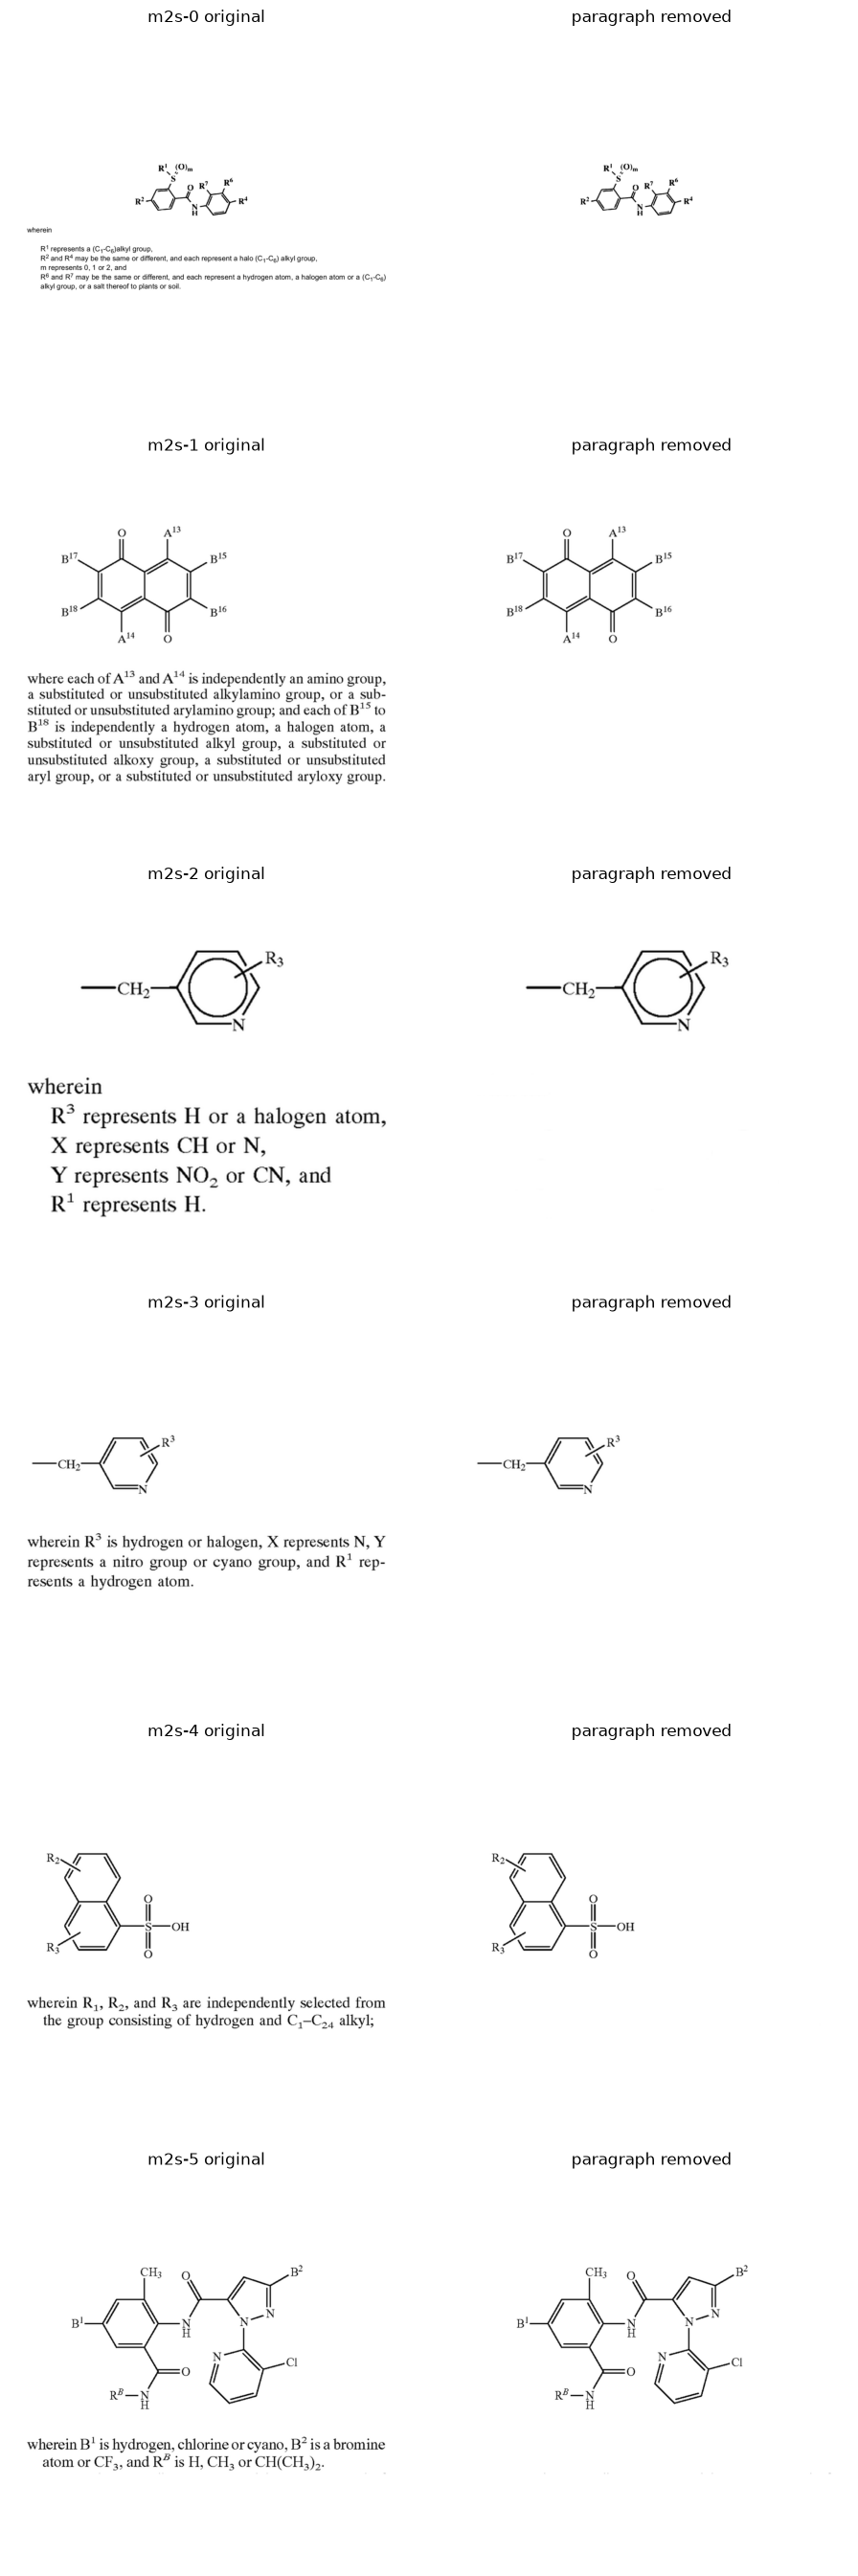

In [4]:
import matplotlib.pyplot as plt

shown = m2s_items[:6]
fig, axes = plt.subplots(len(shown), 2, figsize=(10, 4.5 * len(shown)))
for (ax_orig, ax_masked), item in zip(axes, shown):
    masked, text = structure_only(item)
    ax_orig.imshow(Image.open(m2s_root / item["image"]))
    ax_masked.imshow(masked)
    ax_orig.set_title(f"m2s-{item['id']} original")
    ax_masked.set_title("paragraph removed")
    ax_orig.axis("off")
    ax_masked.axis("off")
plt.tight_layout()

## Tesseract on the paragraph

The paragraph region is cut out with the same split and read with the tesseract command line tool (English, page segmentation mode 6, one uniform block of text).
It is compared with the text of the benchmark cells, both normalized to single spaces, in two ways:

similarity: the ratio from difflib (1.0 means identical). autojunk=False is needed, because by default difflib gives a very low ratio for texts longer than 200 characters even when they are almost the same.

label_recall: how many of the R labels (R1, R2, ...) of the reference appear unchanged in the Tesseract text. Characters like subscripts are the ones that matter in chemistry and the ones OCR often gets wrong, so this is the more important number.

In [5]:
import difflib
import re
import subprocess


def tesseract(image):
    image.save("data/mini/ocr_tmp.png")
    return subprocess.run(["tesseract", "data/mini/ocr_tmp.png", "stdout", "--psm", "6"], capture_output=True, text=True).stdout


def label_recall(reference, prediction):
    """Share of the R labels of the reference (R1, R2, ...) that appear unchanged in the Tesseract text."""
    labels = re.findall(r"\bR\d+\b", reference)
    found = set(re.findall(r"\bR\d+\b", prediction))
    return sum(label in found for label in labels) / len(labels) if labels else None


def paragraph_crop(item):
    image = Image.open(m2s_root / item["image"]).convert("RGB")
    labels, text = split_cells(item["cells"])
    top = min(c["bbox"][1] for c in text)
    return image.crop((0, int((top - 0.01) * image.height), image.width, image.height)), " ".join(" ".join(c["text"].split()) for c in text)


ocr_rows = []
for item in m2s_items[:30]:
    if not split_cells(item["cells"])[1]:
        continue
    crop, reference = paragraph_crop(item)
    prediction = " ".join(tesseract(crop).split())
    ocr_rows.append({
        "id": item["id"],
        "similarity": difflib.SequenceMatcher(None, reference, prediction, autojunk=False).ratio(),
        "label_recall": label_recall(reference, prediction),
        "reference": reference,
        "tesseract": prediction,
    })
ocr_table = pl.DataFrame(ocr_rows)
ocr_table.select("similarity", "label_recall").describe()

statistic,similarity,label_recall
str,f64,f64
"""count""",30.0,19.0
"""null_count""",0.0,11.0
"""mean""",0.966733,0.031579
"""std""",0.025302,0.137649
"""min""",0.910329,0.0
"""25%""",0.944954,0.0
"""50%""",0.975309,0.0
"""75%""",0.987179,0.0
"""max""",1.0,0.6


In [6]:
for row in ocr_table.filter(pl.col("label_recall").is_not_null()).sort("label_recall").head(3).iter_rows(named=True):
    print(f"m2s-{row['id']}  similarity {row['similarity']:.2f}, label recall {row['label_recall']:.2f}")
    print("cells:    ", row["reference"][:300])
    print("tesseract:", row["tesseract"][:300])
    print()

m2s-2  similarity 0.97, label recall 0.00
cells:     wherein R3 represents H or a halogen atom, X represents CH or N, Y represents NO2 or CN, and R1 represents H.
tesseract: wherein R? represents H or a halogen atom, X represents CH or N, Y represents NO, or CN, and R* represents H.

m2s-3  similarity 0.98, label recall 0.00
cells:     wherein R3 is hydrogen or halogen, X represents N, Y represents a nitro group or cyano group, and R1 rep- resents a hydrogen atom.
tesseract: wherein R® is hydrogen or halogen, X represents N, Y represents a nitro group or cyano group, and R? rep- resents a hydrogen atom.

m2s-4  similarity 0.94, label recall 0.00
cells:     wherein R1, R2, and R3 are independently selected from the group consisting of hydrogen and C1-C24 alkyl;
tesseract: wherein R,, R,, and R, are independently selected from the group consisting of hydrogen and C,—-C,, alkyl;



## MG1 synthetic

Streamed, so only the first rows are downloaded. The dataset of the MarkushGrapher authors keeps the page image, the OCR cells and a description column, which should be the paragraph text.

In [7]:
from datasets import load_dataset

mg1 = load_dataset("docling-project/MarkushGrapher-Datasets", "markushgrapher-synthetic-training", split="train", streaming=True)
mg1_rows = list(mg1.take(40))
mg1_rows[0].keys()

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

dict_keys(['id', 'page_image_path', 'description', 'annotation', 'mol', 'cxsmiles_dataset', 'cxsmiles', 'cxsmiles_opt', 'keypoints', 'cells', 'page_image'])

In [8]:
import re


def stable_text(annotation):
    match = re.search(r"<stable>(.*?)</stable>", annotation, re.S)
    return match.group(1) if match else ""


pl.DataFrame([{
    "id": r["id"],
    "description_chars": len(r["description"] or ""),
    "cells": len(r["cells"]),
    "stable_chars": len(stable_text(r["annotation"])),
} for r in mg1_rows]).describe()

statistic,id,description_chars,cells,stable_chars
str,f64,f64,f64,f64
"""count""",40.0,40.0,40.0,40.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",1.7415e6,226.425,12.9,136.925
"""std""",785352.758616,155.600884,5.309884,121.603683
"""min""",246109.0,0.0,3.0,0.0
"""25%""",1.139778e6,128.0,10.0,33.0
"""50%""",1.837429e6,209.0,13.0,141.0
"""75%""",2.336646e6,311.0,14.0,178.0
"""max""",3.23858e6,709.0,33.0,539.0


1837429
description: 'in which R, and R0 are independendly selected from iodine, a C1-C8 alkyl group, -CF(CH3)2, a substituted or unsubstituted C3 to C20 cycloalkyll group, C3-C7cycloalkyl, C1-C4 alkyl, an aryl, a halogen atom, an aryl group, and 1-5-halogeno-C1-4-alkoxy, L30 represents —SO2, Rr is as defined in claim 1, Q is an integer of 9 to 14.'
stable:      'R<n>R0:iodine<n>a C1-C8 alkyl group<n>-CF(CH3)2<n>a substituted or unsubstituted C3 to C20 cycloalkyll group<n>C3-C7cycloalkyl<n>C1-C4 alkyl<n>an aryl<n>a halogen atom<n>an aryl group<n>1-5-halogeno-C1-4-alkoxy<ns>L30:—SO2<ns>Rr:as defined in claim 1<ns>Q:9-14'

1080419
description: 'wherein \n0: E is a single bond.'
stable:      'E:a single bond'

1464600
description: 'wherein \nL2 is O, a 6-membered heteroaryl ring having 1 or 2 nitrogen atoms, Se, N—R1, a single bond, optional, S, a hydrocarbon group, —SO2, and N-aryl.'
stable:      'L2:O<n>a 6-membered heteroaryl ring having 1 or 2 nitrogen atoms<n>Se<n>N—R1<n>a single bon

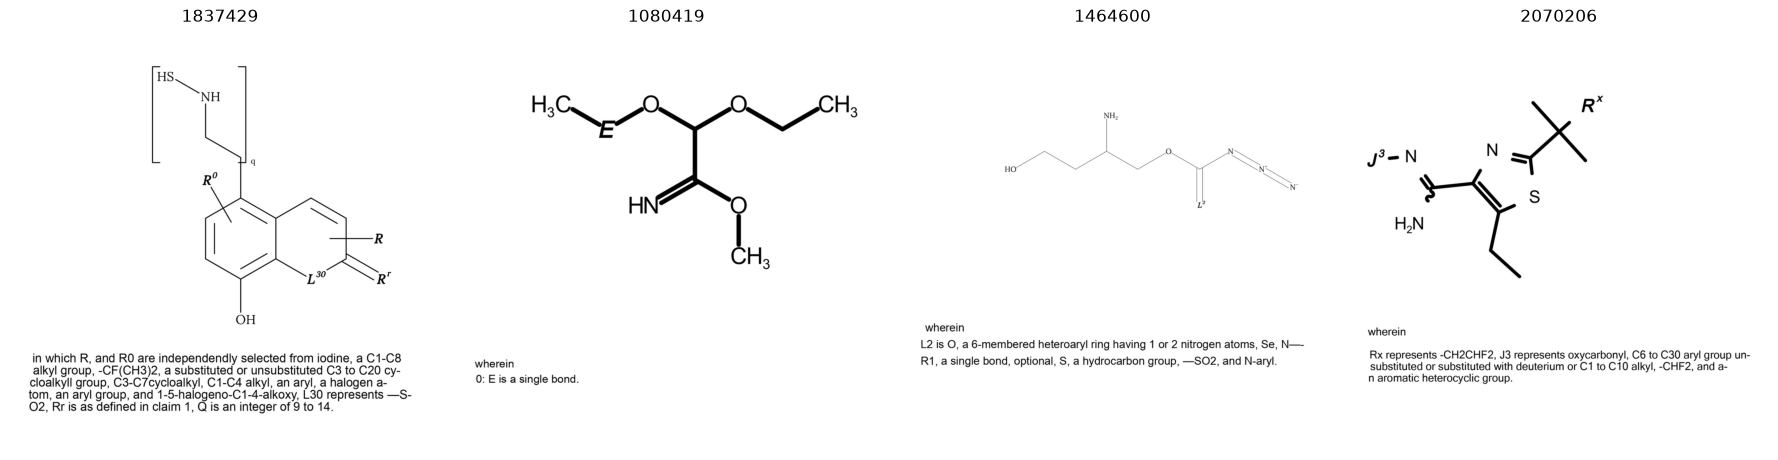

In [9]:
shown = mg1_rows[:4]
fig, axes = plt.subplots(1, len(shown), figsize=(4.5 * len(shown), 4.5))
for ax, r in zip(axes, shown):
    ax.imshow(r["page_image"])
    ax.set_title(str(r["id"]))
    ax.axis("off")
plt.tight_layout()

for r in shown:
    print(r["id"])
    print("description:", repr(r["description"]))
    print("stable:     ", repr(stable_text(r["annotation"])))
    print()

## The model from 05 on the structure only

In [11]:
import torch
from peft import PeftModel
from transformers import AutoModelForImageTextToText, AutoProcessor

BASE_MODEL = "Qwen/Qwen3.5-0.8B-Base"
ADAPTER_DIR = Path("data/lora_0.8b_molparser_peft_norm/adapter")
DEVICE = "cuda"

processor = AutoProcessor.from_pretrained(BASE_MODEL)
processor.tokenizer.padding_side = "right"
processor.chat_template = processor.tokenizer.chat_template
processor.image_processor.size = {"shortest_edge": 65536, "longest_edge": 512 * 32 * 32}  # same cap as in training

model = AutoModelForImageTextToText.from_pretrained(BASE_MODEL, dtype=torch.bfloat16).to(DEVICE)
model = PeftModel.from_pretrained(model, ADAPTER_DIR)
model.eval()
base = model.base_model.model

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

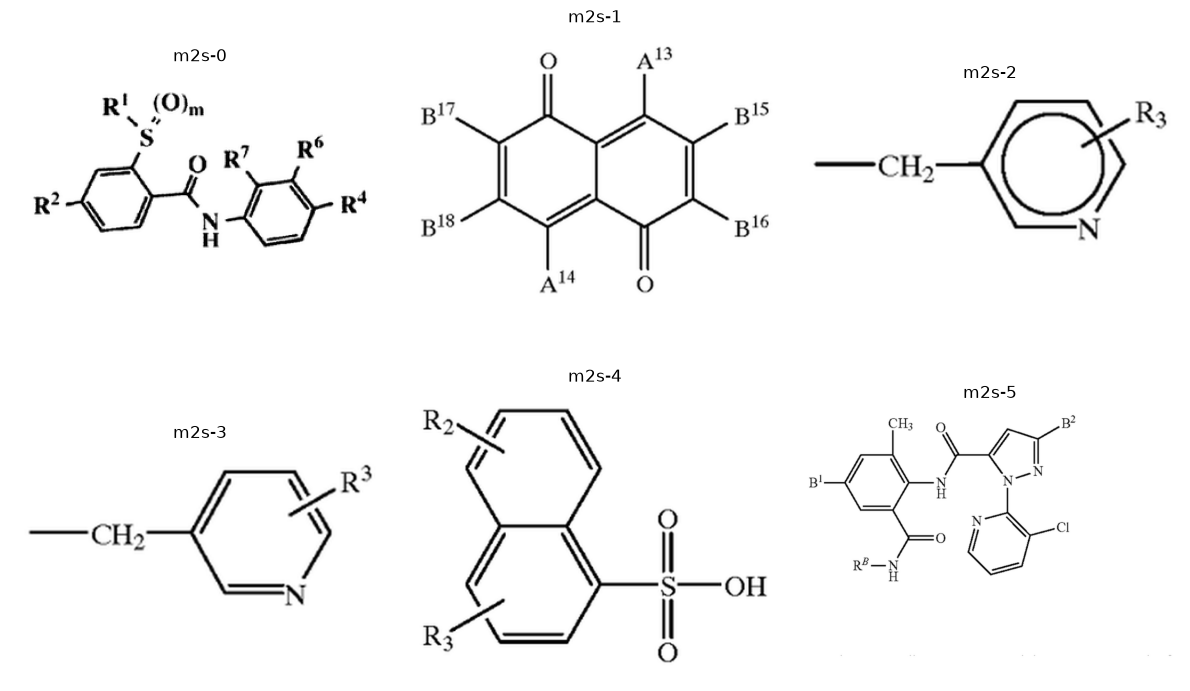

In [12]:
def structure_crop(item, pad=20):
    """Paragraph painted white, then trimmed to the area with dark pixels."""
    image, _ = structure_only(item)
    box = image.convert("L").point(lambda p: 255 if p < 200 else 0).getbbox()
    if box is None:
        return image
    left, top, right, bottom = box
    return image.crop((max(left - pad, 0), max(top - pad, 0), min(right + pad, image.width), min(bottom + pad, image.height)))


shown = m2s_items[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, item in zip(axes.flat, shown):
    ax.imshow(structure_crop(item))
    ax.set_title(f"m2s-{item['id']}")
    ax.axis("off")
plt.tight_layout()

Check the crops above before running the predictions: the structure must not be cut and no paragraph line should be left.

In [13]:
from tqdm.auto import tqdm

from glyph.markush.grading import grade

IM_END = processor.tokenizer.convert_tokens_to_ids("<|im_end|>")


def prompt_text(user_text):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {
                "type": "text",
                "text": user_text
            }
        ]
    }]
    return processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)


@torch.no_grad()
def predict_image(image, user_text, max_new_tokens=768):
    inputs = processor(text=[prompt_text(user_text)], images=[image], return_tensors="pt").to(DEVICE)
    out = base.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, eos_token_id=IM_END, pad_token_id=IM_END)
    return processor.tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


variants = {
    "full image": lambda item: Image.open(m2s_root / item["image"]).convert("RGB"),
    "structure only": structure_crop,
}
structure_predictions = {}
for name, get_image in variants.items():
    structure_predictions[name] = [predict_image(get_image(item), item["prompt"]) for item in tqdm(m2s_items, desc=name)]
Path("data/lora_0.8b_molparser_peft_norm/m2s_structure_predictions.json").write_text(json.dumps(structure_predictions))

full image:   0%|          | 0/103 [00:00<?, ?it/s]

structure only:   0%|          | 0/103 [00:00<?, ?it/s]

43283

In [14]:
metrics = ["valid_pred", "backbone_inchi_match", "cxsmiles_full_match", "r_full_match"]


def scores(predictions):
    samples = [grade(p, item["annotation"])["sample"] for item, p in zip(m2s_items, predictions)]
    return pl.DataFrame([{m: float(s.get(m) or 0) for m in metrics} for s in samples]).mean()


pl.concat([
    scores(predictions).with_columns(pl.lit(name).alias("input"))
    for name, predictions in structure_predictions.items()
]).select("input", *metrics)

input,valid_pred,backbone_inchi_match,cxsmiles_full_match,r_full_match
str,f64,f64,f64,f64
"""full image""",0.854369,0.262136,0.184466,0.281553
"""structure only""",1.0,0.38835,0.31068,0.485437


## Reading the paragraph with plain Qwen

In [ ]:
import unicodedata

items_by_id = {item["id"]: item for item in m2s_items}


def qwen_read(image):
    with model.disable_adapter():
        text = predict_image(image, "Transcribe all the text in this image. Return the text only, no other text.")
    return unicodedata.normalize("NFKC", text).replace("**", "")


qwen_rows = []
for row in tqdm(list(ocr_table.iter_rows(named=True))):
    crop, reference = paragraph_crop(items_by_id[row["id"]])
    prediction = " ".join(qwen_read(crop).split())
    qwen_rows.append({
        "id": row["id"],
        "similarity": difflib.SequenceMatcher(None, reference, prediction, autojunk=False).ratio(),
        "label_recall": label_recall(reference, prediction),
        "reference": reference,
        "qwen": prediction,
    })
qwen_table = pl.DataFrame(qwen_rows)

pl.DataFrame({
    "reader": ["Tesseract", "Qwen3.5-0.8B-Base"],
    "similarity": [ocr_table["similarity"].mean(), qwen_table["similarity"].mean()],
    "label_recall": [ocr_table["label_recall"].mean(), qwen_table["label_recall"].mean()],
})

  0%|          | 0/30 [00:00<?, ?it/s]

reader,similarity,label_recall
str,f64,f64
"""Tesseract""",0.966733,0.031579
"""Qwen3.5-0.8B-Base""",0.98499,0.894737


In [23]:
for row in qwen_table.sort("similarity").head(3).iter_rows(named=True):
    print(f"m2s-{row['id']}  similarity {row['similarity']:.2f}")
    print("cells:", row["reference"][:300])
    print("qwen: ", row["qwen"][:300])
    print()

m2s-10  similarity 0.93
cells: wherein R4 is selected from the group consisting of C7-C24 alkyl and C2-C24 alkenyl-CH2-, each R5 independently is a straight chain or branched C2-C4 alkylene, x is a number from 1-50 and y is a number from 0 to 50, wherein the salt compound has a pH of 4 to 6.
qwen:  wherein $R_4$ is selected from the group consisting of $C_7-C_{24}$ alkyl and $C_2-C_{24}$ alkenyl-$CH_2-$, each $R_5$ independently is a straight chain or branched $C_2-C_4$ alkylene, $x$ is a number from $1-50$ and $y$ is a number from $0$ to $50$, wherein the salt compound has a pH of $4$ to $6$.

m2s-4  similarity 0.93
cells: wherein R1, R2, and R3 are independently selected from the group consisting of hydrogen and C1-C24 alkyl;
qwen:  wherein $R_1$, $R_2$, and $R_3$ are independently selected from the group consisting of hydrogen and $C_1-C_{24}$ alkyl;

m2s-8  similarity 0.95
cells: wherein: R and R1 are as described hereinabove; and L is halogen or sulfonate;
qwen:  wherein: R and R1

### Side by side

Five random paragraph crops with the text read by Tesseract and by Qwen below. Change the seed to see other examples.


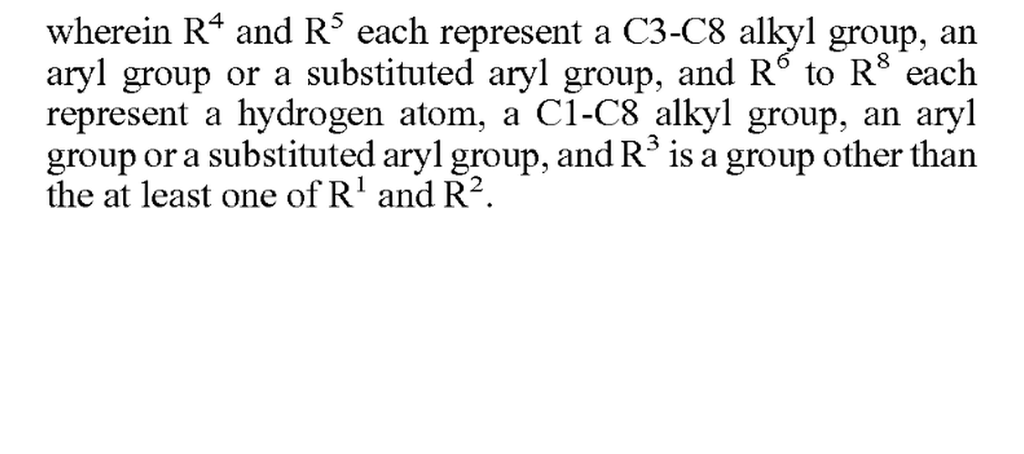
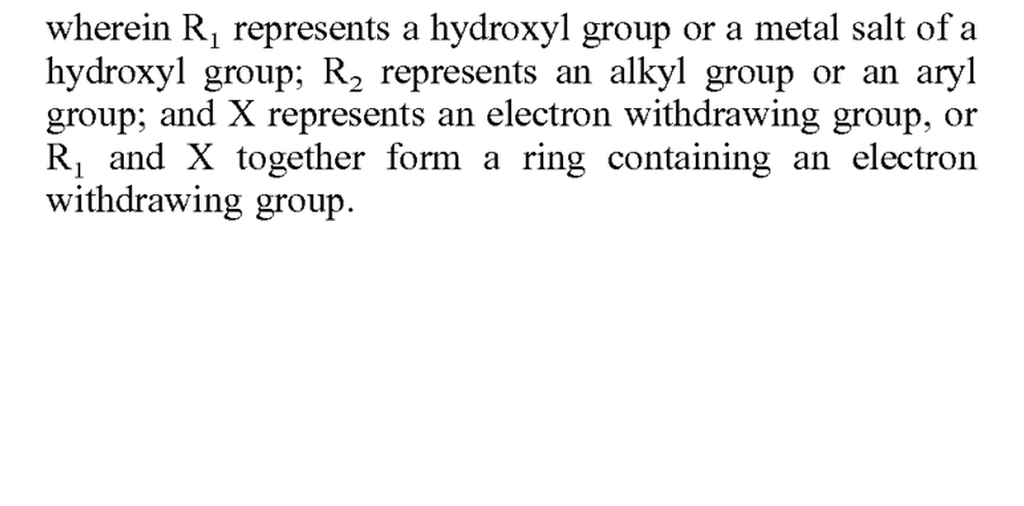
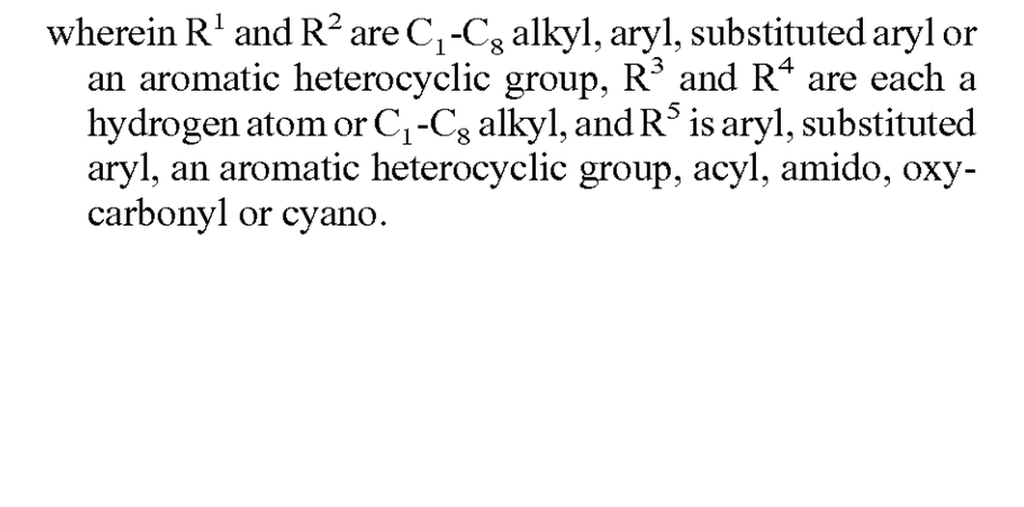
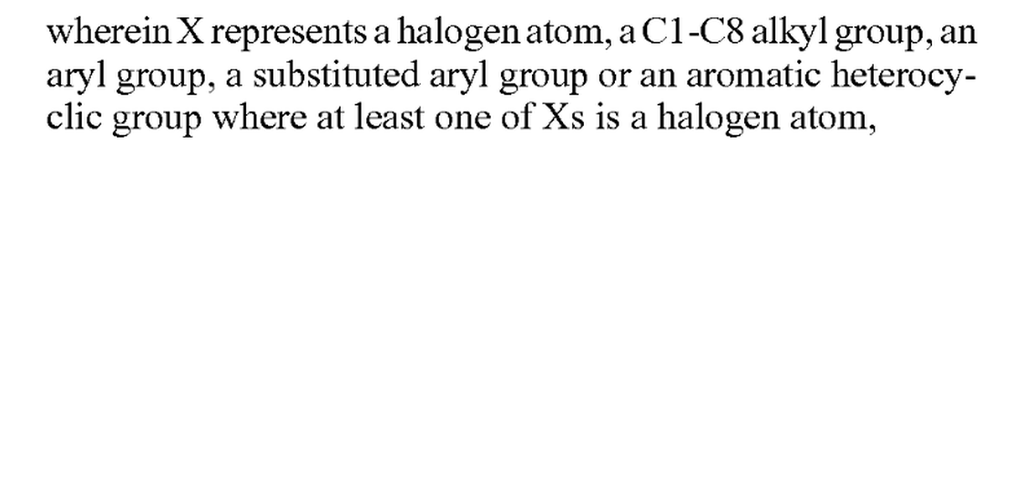
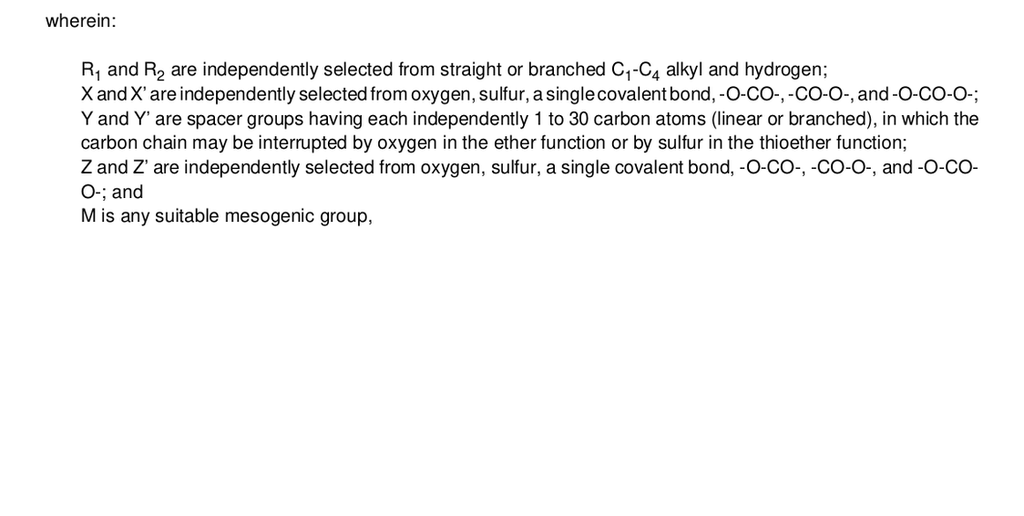

In [24]:
import base64
import io
import random
from html import escape

from IPython.display import HTML, display


def png_base64(image):
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    return base64.b64encode(buffer.getvalue()).decode()


tesseract_text = dict(zip(ocr_table["id"], ocr_table["tesseract"]))
qwen_text = dict(zip(qwen_table["id"], qwen_table["qwen"]))
box = "border:1px solid #ccc; padding:8px; margin:4px 0; background:white; color:black; white-space:pre-wrap; font-family:monospace; font-size:13px"

page = ""
for item_id in random.Random(0).sample(list(qwen_text), 5):
    crop, _ = paragraph_crop(items_by_id[item_id])
    page += (
        f"<h4>m2s-{item_id}</h4>"
        f"<img src='data:image/png;base64,{png_base64(crop)}' style='max-width:700px; width:100%'>"
        f"<div style='{box}'><b>Tesseract:</b> {escape(tesseract_text[item_id])}</div>"
        f"<div style='{box}'><b>Qwen:</b> {escape(qwen_text[item_id])}</div><hr>"
    )
display(HTML(page))

## Paragraph text in the prompt

In [25]:
def paragraph_cells_text(item):
    return "\n".join(c["text"] for c in split_cells(item["cells"])[1])


paragraph_text = {
    "text read by Qwen": [qwen_read(paragraph_crop(item)[0]) for item in tqdm(m2s_items, desc="reading")],
    "text from benchmark cells": [paragraph_cells_text(item) for item in m2s_items],
}

with_text = {"structure only": structure_predictions["structure only"]}
for name, texts in paragraph_text.items():
    with_text[f"structure only + {name}"] = [
        predict_image(structure_crop(item), f"OCR text: {text}\n{item['prompt']}")
        for item, text in zip(tqdm(m2s_items, desc=name), texts)
    ]
Path("data/lora_0.8b_molparser_peft_norm/m2s_text_prompt_predictions.json").write_text(json.dumps(with_text))

reading:   0%|          | 0/103 [00:00<?, ?it/s]

text read by Qwen:   0%|          | 0/103 [00:00<?, ?it/s]

text from benchmark cells:   0%|          | 0/103 [00:00<?, ?it/s]

47135

In [26]:
pl.concat([
    scores(predictions).with_columns(pl.lit(name).alias("input"))
    for name, predictions in with_text.items()
]).select("input", *metrics)

input,valid_pred,backbone_inchi_match,cxsmiles_full_match,r_full_match
str,f64,f64,f64,f64
"""structure only""",1.0,0.38835,0.31068,0.485437
"""structure only + text read by …",0.970874,0.398058,0.31068,0.485437
"""structure only + text from ben…",0.970874,0.38835,0.300971,0.475728


How many predictions differ from the ones without text at all (if the text is ignored, this is close to 0).

In [27]:
baseline = with_text["structure only"]
pl.DataFrame({
    "input": list(with_text),
    "share_changed": [sum(p != b for p, b in zip(predictions, baseline)) / len(baseline) for predictions in with_text.values()],
})

input,share_changed
str,f64
"""structure only""",0.0
"""structure only + text read by …",0.446602
"""structure only + text from ben…",0.475728
